In [4]:
import sqlite3
import pandas as pd

conexao = sqlite3.connect("dados/academia.db")

pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type = 'table'",
    conexao
)

,name
0,unidades
1,planos
2,alunos
3,matriculas
4,pagamentos
5,checkins


In [5]:
tabelas = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type = 'table'",
    conexao
)["name"]

for t in tabelas:
    print(t)
    display(pd.read_sql_query(f"PRAGMA table_info({t})", conexao)[["name", "type"]])

unidades


,name,type
0,id_unidade,INTEGER
1,nome,TEXT
2,regiao,TEXT
3,data_abertura,TEXT
4,qtd_equipamentos,INTEGER


planos


,name,type
0,id_plano,INTEGER
1,nome_plano,TEXT
2,preco_tabela,REAL


alunos


...

,name,type
0,id_matricula,INTEGER
1,id_aluno,INTEGER
2,id_unidade,INTEGER
3,id_plano,INTEGER
4,data_inicio,TEXT
5,data_fim,TEXT
6,status,TEXT
7,motivo_cancelamento,TEXT
8,valor_mensal,REAL


pagamentos


,name,type
0,id_pagamento,INTEGER
1,id_matricula,INTEGER
2,data_vencimento,TEXT
3,data_pagamento,TEXT
4,valor,REAL
5,status,TEXT


checkins


,name,type
0,id_checkin,INTEGER
1,id_matricula,INTEGER
2,data_hora,TEXT


In [9]:
checkins = pd.read_sql_query("SELECT * FROM checkins", conexao)
checkins

,id_checkin,id_matricula,data_hora
0,1,376,2025-06-19 18:29:31
1,2,36,2026-08-08 20:54:17
2,3,412,2025-12-02 08:02:56
3,4,391,2025-06-08 18:42:22
4,5,1001,2024-08-20 13:56:33
...,...,...,...
275005,275006,1865,2025-08-31 11:35:51
275006,275007,1340,2025-08-02 08:56:03
275007,275008,68,2026-05-13 17:02:48
275008,275009,1248,2025-12-14 17:03:13


In [10]:
checkins["hora"] = pd.to_datetime(checkins["data_hora"]).dt.hour
checkins[["data_hora", "hora"]].head()

,data_hora,hora
0,2025-06-19 18:29:31,18
1,2026-08-08 20:54:17,20
2,2025-12-02 08:02:56,8
3,2025-06-08 18:42:22,18
4,2024-08-20 13:56:33,13


In [11]:
checkins["hora"].min(), checkins["hora"].max()

(np.int32(6), np.int32(22))

In [12]:
checkins["faixa"] = (checkins["hora"] // 2) * 2
checkins[["hora", "faixa"]].drop_duplicates().sort_values("hora")

,hora,faixa
8,6,6
12,7,6
2,8,8
38,9,8
56,10,10
51,11,10
16,12,12
4,13,12
24,14,14
53,15,14


In [14]:
matriculas = pd.read_sql_query("SELECT * FROM matriculas", conexao)
print(list(matriculas.columns))
print(list(checkins.columns))

['id_matricula', 'id_aluno', 'id_unidade', 'id_plano', 'data_inicio', 'data_fim', 'status', 'motivo_cancelamento', 'valor_mensal']
['id_checkin', 'id_matricula', 'data_hora', 'hora', 'faixa']


In [15]:
base = checkins.merge(
    matriculas[["id_matricula", "id_unidade"]],
    on="id_matricula",
    how="left"
)
base.head()

,id_checkin,id_matricula,data_hora,hora,faixa,id_unidade
0,1,376,2025-06-19 18:29:31,18,18,3
1,2,36,2026-08-08 20:54:17,20,20,1
2,3,412,2025-12-02 08:02:56,8,8,4
3,4,391,2025-06-08 18:42:22,18,18,3
4,5,1001,2024-08-20 13:56:33,13,12,3


In [16]:
print(len(checkins), len(base))
print(base["id_unidade"].isna().sum())

275010 275010
0


In [17]:
contagem = base.groupby(["id_unidade", "faixa"]).size().reset_index(name="qtd")
contagem

,id_unidade,faixa,qtd
0,1,6,16046
1,1,8,8489
2,1,10,4657
3,1,12,8656
4,1,14,3712
5,1,16,11332
6,1,18,17955
7,1,20,8293
8,1,22,929
9,2,6,11269


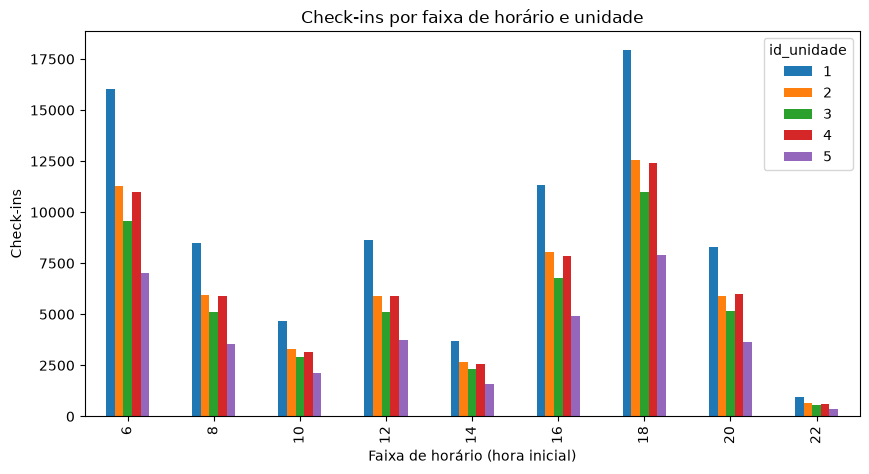

In [20]:
import matplotlib.pyplot as plt

tabela = contagem.pivot(index="faixa", columns="id_unidade", values="qtd")
tabela.plot(kind="bar", figsize=(10, 5))
plt.xlabel("Faixa de horário (hora inicial)")
plt.ylabel("Check-ins")
plt.title("Check-ins por faixa de horário e unidade")
plt.show()

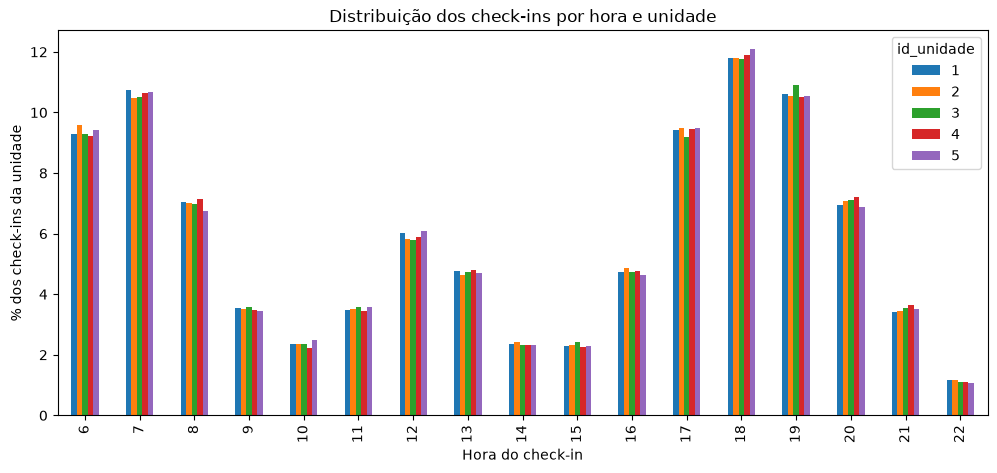

In [21]:
por_hora = base.groupby(["id_unidade", "hora"]).size().reset_index(name="qtd")
por_hora["pct"] = por_hora["qtd"] / por_hora.groupby("id_unidade")["qtd"].transform("sum") * 100

tabela = por_hora.pivot(index="hora", columns="id_unidade", values="pct")
tabela.plot(kind="bar", figsize=(12, 5))
plt.xlabel("Hora do check-in")
plt.ylabel("% dos check-ins da unidade")
plt.title("Distribuição dos check-ins por hora e unidade")
plt.show()